# Receptive-field orientation → `ordinal_rf_orientation.pdf`

Where a neuron's fitted 2-object phase sits **relative to its own 1-object receptive field**,
over every bootstrap. Rows are the two models, columns the two monkeys; zero means the 2-object
tuning sits on the 1-object field. The uniform (null) level is available as `NULL_LINE`
and is off here; the uniformity tests at the bottom are what actually decide against it.

Two things differ from figure 3's version:

* the **1-object receptive field is measured the same way as the 2-object phase** — by the same
  pairwise comparison, with no anchor, rather than by fitting a cosine. The plotted quantity is
  then a difference of two phases estimated by one estimator, which figure 3's is not;
* the **exclusion criterion is a prerequisite of the measurement**, not a threshold on model
  fit. A neuron enters a row only if its phase is *determinable* — a Wald test on γ against its
  bootstrap covariance, Benjamini–Hochberg corrected across neurons — applied to the row's own
  model and to the 1-object reference, since the plotted quantity is their difference. A second
  criterion, a ceiling on the bootstrap circular s.d. of the phase, was removed after being
  measured: at 30° it excluded zero neurons on the 2-object phase, because determinacy is
  strictly the harder test on this data (see `stats_lib.phase_eligible`).

The relational phase is an **orientation** (period 180°), so subtracting a direction leaves a
180° ambiguity and each neuron contributes two values; the retinotopic phase is a direction and
contributes one. Same convention as figure 3.

In [1]:
import sys

import matplotlib.pyplot as plt

sys.path.append('..')
import common

common.set_style()
import stats_lib as sl

FIGSIZE = (5.7, 4.1)
OUTPUT = 'rf_orientation.pdf'

N_BINS = 40
NULL_LINE = False         # the horizontal rule at 1/N_BINS — the density a uniform
                          # distribution would have. True restores it.
# The shared population criterion (config.FDR_Q + config.MIN_DEV, via neuron_selection.py),
# ON as in every other analysis in the paper. It was off here until 2026-09-13 — by omission
# rather than by choice, since `stats_lib.APPLY_MODULATION_CRITERION` defaults to False — so
# this panel was drawn over all 3186 fit neurons while the model-comparison panel beside it
# used 1339. The phase-determinacy test below is much the stricter of the two, so the
# histograms barely move; what changes is that the two panels now describe the same neurons.
APPLY_MODULATION_CRITERION = True

PHASE_FDR_Q = sl.PHASE_FDR_Q        # determinacy: BH across neurons
INSET_SHIFTS_DEG = (-90, 0, 90, 180)   # where the insets sit on the x axis
INSET_RF_DEG = 90.0       # the 1-object receptive field every inset is measured against
INSET_SEP_DEG = 90.0      # inter-object angle of the chords inside each inset
INSET_N_ORIENT = 4        # chords per ring — four at 90 deg apart make the square v1 draws
INSET_SIZE_IN = 0.55      # side of an inset, in INCHES (they are square)
INSET_Y = 1.02            # bottom edge, in panel heights above the axis
INSET_TITLE_PAD = 6      # HEIGHT OF THE COLUMN TITLES, in points above the axes. Measured,
                          # the clear gap above the insets is (pad - 3) pt, and it floors at
                          # 0 -- the title will not drop onto them however small this goes.
INSET_RADIUS = 0.38       # chord endpoints, in axes fractions from the inset's centre
INSET_ANNULUS_R = 0.44    # the 1-object annulus ...
INSET_ANNULUS_W = 0.06    # ... and its band width
INSET_LINEWIDTH = 2.0
ROW_HSPACE = 0.3         # VERTICAL WHITESPACE between the two model rows, as a fraction of
                          # axes height. Applied to the layout engine before anything is
                          # placed. Small values are fine: an inset overhanging the row above
                          # is drawn over it (insets are clip_on=False), it is not cut off.
INSET_CONNECTOR_COLOR = '0.75'   # the line tying an inset to its x value: a pointer, not a
INSET_CONNECTOR_LW = 0.9         # datum, so it must never compete with the bars

# ── The inset key (`rf_orientation_inset_key.pdf`) ───────────────────────────
# A legend for the tuning insets: what their two parts ARE, with no data in either. Ported
# from an earlier version of this figure.
OUTPUT_KEY = 'rf_orientation_inset_key.pdf'
KEY_FIGSIZE = (1.0, 1.0)
KEY_SEP_DEG = 90.0        # inter-object angle of the chords; 4 of them at 90 deg make a square
KEY_N_ORIENT = 4          # chord midpoints
KEY_RADIUS = 0.38         # chord endpoints, in axes fractions from the centre
KEY_ANNULUS_R = 0.44      # the 1-object annulus ...
KEY_ANNULUS_W = 0.06      # ... and its band width
KEY_LINEWIDTH = 2.0
KEY_RING_COLOR = '0.65'   # the annulus, and by default its label
KEY_RAY_COLOR = '0.05'    # the chords, and by default their label
KEY_LABELS = ('1-obj', '2-obj')
# Label placement, in axes fractions from the centre, and rotation in degrees. The 1-obj
# label is laid ALONG the annulus; the 2-obj label sits inside the square the chords enclose.
KEY_RING_LABEL_XY, KEY_RING_LABEL_ROT = (0.42, 0.33), -49.0
KEY_RAY_LABEL_XY, KEY_RAY_LABEL_ROT = (0.0, -0.13), 0.0

# The uniformity tests at the bottom draw their null instead of assuming an asymptotic form,
# so MC_DRAWS sets both the runtime and the floor on a reportable p: 1 / (MC_DRAWS + 1).
MC_DRAWS = 10000
MC_SEED = 0

In [2]:
units = sl.select_units(sl.load_units(), apply_modulation=APPLY_MODULATION_CRITERION)
phases = sl.load_phases()
for s in sl.ordered_subjects(units):
    g = units[units['subject'] == s]
    print(f'{sl.subject_title(s)}: {len(g)} neurons from {g["session"].nunique()} sessions')

2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 3186 -> 1339 neurons
Monkey P: 998 neurons from 10 sessions
Monkey E: 341 neurons from 12 sessions


## What the criteria cost

Printed before the figure, so the price of each prerequisite is visible rather than implied.

In [3]:
sl.exclusion_report(units, q=PHASE_FDR_Q)

,model,n,determinate_2obj,determinate_1obj,enough_1obj_trials,all_criteria
0,Retinotopic,1339,1080,919,1244,787
1,Relational,1339,1208,919,1244,807


In [4]:
# 1-object modulation per monkey, by this figure's own 1-object criterion (`sl.phase_eligible`'s
# reference half): a determinable 1-object receptive field -- the Wald test `oneobj_p`, BH at
# PHASE_FDR_Q across all of `units` at once (as above, not per monkey) -- and at least
# config.MIN_1OBJ_TRIALS 1-object trials.
import numpy as np
det_1 = sl.bh_reject(units['oneobj_p'].to_numpy(float), PHASE_FDR_Q)
enough_1 = units['n_1obj'].to_numpy(float) >= sl.config.MIN_1OBJ_TRIALS
for s in sl.ordered_subjects(units):
    m = (units['subject'] == s).to_numpy()
    n, k = int(m.sum()), int((det_1 & enough_1 & m).sum())
    print(f'{sl.subject_title(s)}: {k} of {n} neurons ({k / n:.1%}) are 1-object modulated '
          f'(determinable 1-object RF: {int((det_1 & m).sum())}; >= '
          f'{sl.config.MIN_1OBJ_TRIALS} 1-object trials: {int((enough_1 & m).sum())})')


Monkey P: 692 of 998 neurons (69.3%) are 1-object modulated (determinable 1-object RF: 731; >= 100 1-object trials: 925)
Monkey E: 183 of 341 neurons (53.7%) are 1-object modulated (determinable 1-object RF: 188; >= 100 1-object trials: 319)


In [5]:
# The tuning insets are drawn by `stats_lib.add_shift_insets`, beside `plot_phase_histograms`:
# the per-area and single-unit supplements draw the same figure over a subset of these neurons
# and call the same function, so the three cannot drift apart.


Phase relative to the 1-object receptive field (all bootstraps):
  Monkey P —   Retinotopic: 623/998 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey P —   Relational: 646/998 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey E —   Retinotopic: 153/341 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey E —   Relational: 153/341 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)


saved rf_orientation.pdf


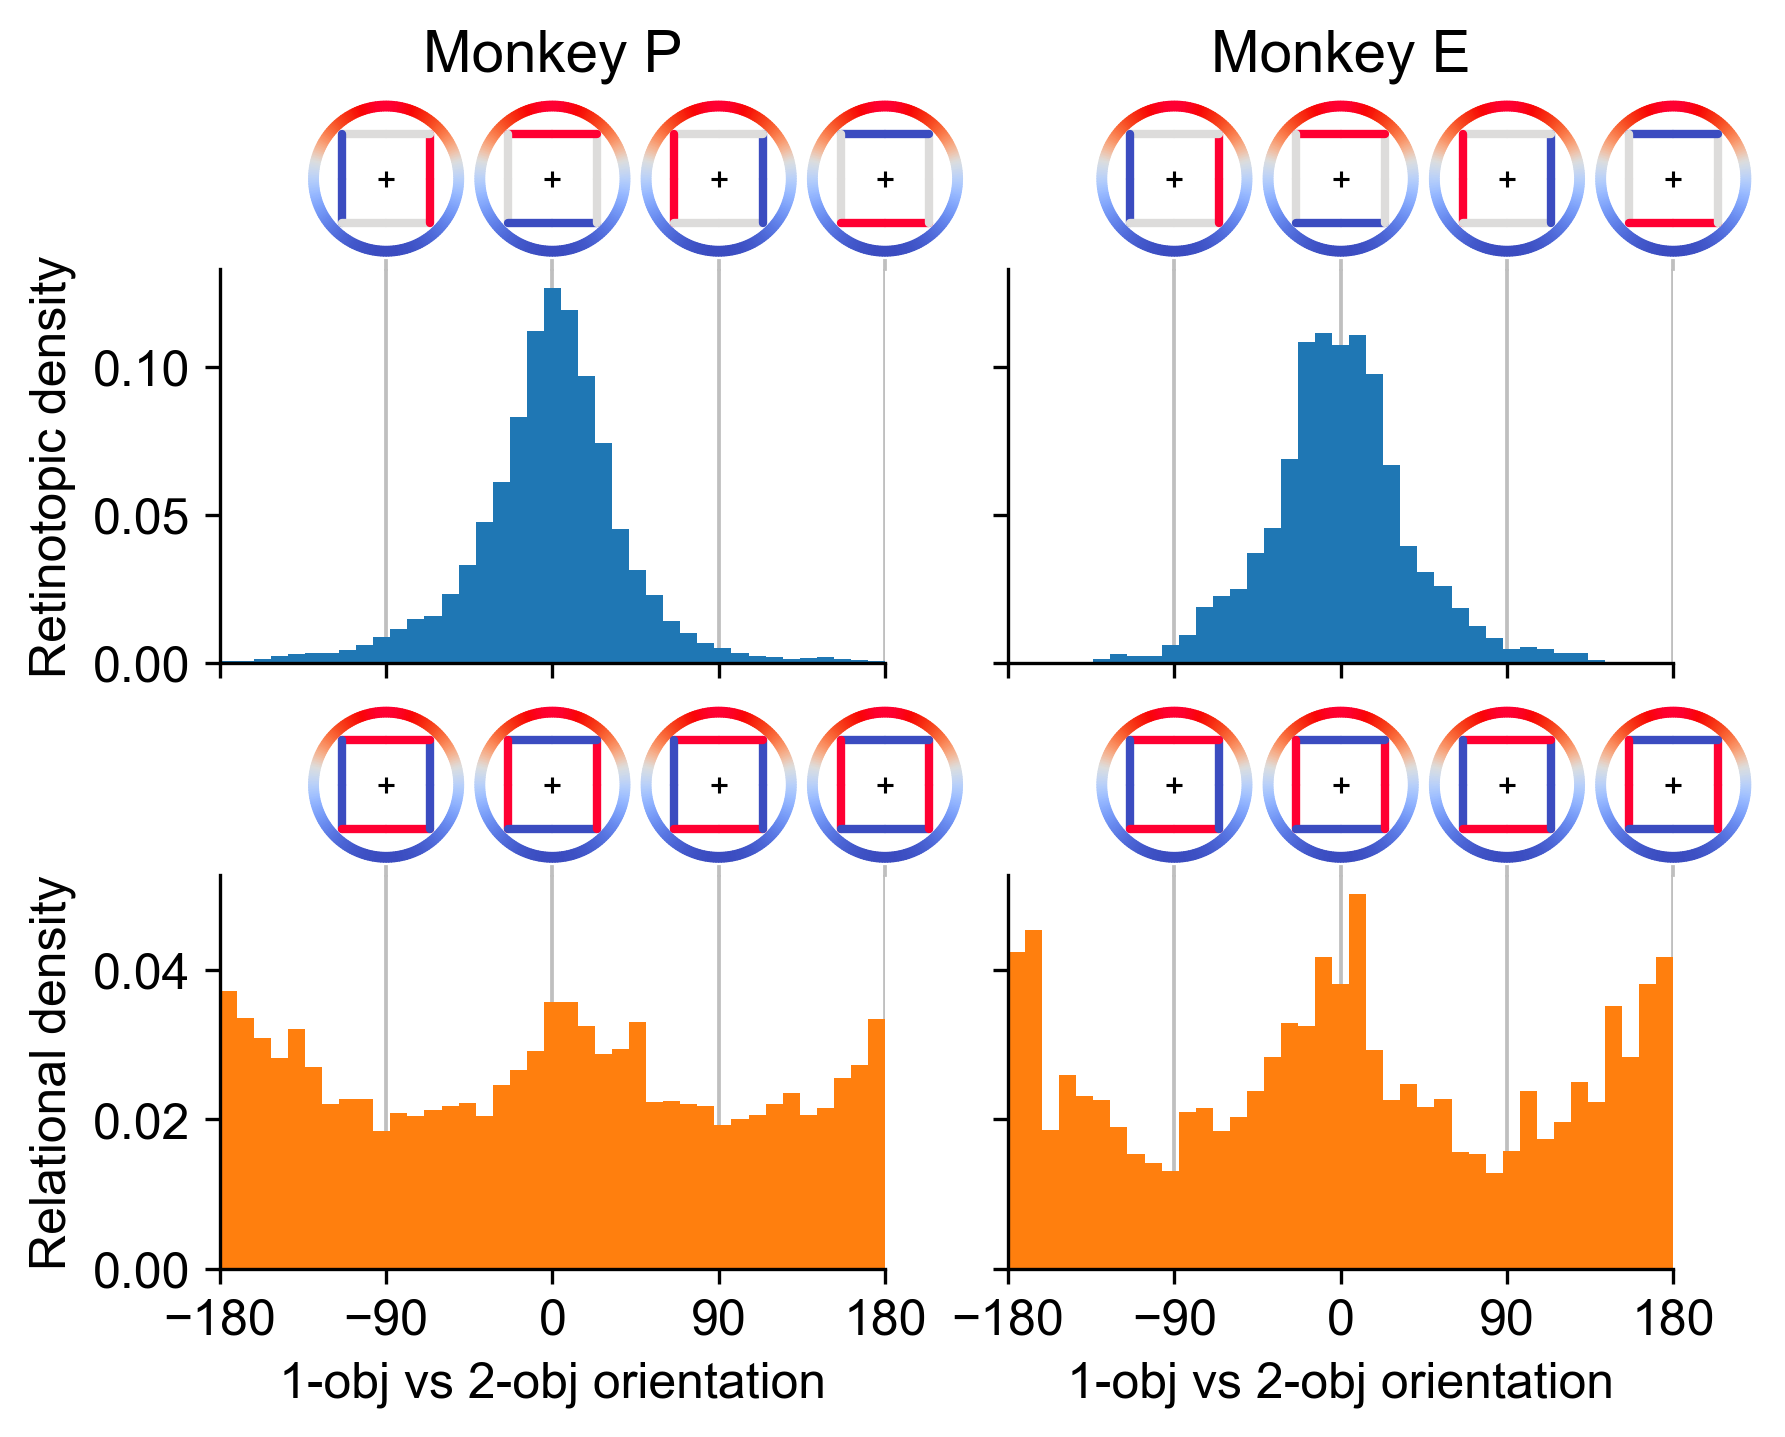

In [6]:
fig, axes = sl.plot_phase_histograms(
    units, phases, n_bins=N_BINS, figsize=FIGSIZE, share_y='row', q=PHASE_FDR_Q,
    null_line=NULL_LINE)
sl.add_shift_insets(fig, axes, sl.PHASE_MODELS, shifts_deg=INSET_SHIFTS_DEG,
                 rf_deg=INSET_RF_DEG, size_in=INSET_SIZE_IN, y=INSET_Y,
                 title_pad=INSET_TITLE_PAD, sep_deg=INSET_SEP_DEG,
                 n_orientations=INSET_N_ORIENT, radius=INSET_RADIUS,
                 annulus_radius=INSET_ANNULUS_R, annulus_width=INSET_ANNULUS_W,
                 linewidth=INSET_LINEWIDTH, hspace=ROW_HSPACE,
                 connector_color=INSET_CONNECTOR_COLOR, connector_lw=INSET_CONNECTOR_LW)
common.save(fig, OUTPUT)
plt.show()

## Is any of it distinguishable from uniform?

A p-value per panel, because "the histogram looks peaked" is not a result. Two tests, both with
their p sampled from the null directly rather than taken from an asymptotic formula, so the
smallest reportable value is `1 / (MC_DRAWS + 1)`:

* **Rayleigh** — the resultant length. Sensitive to a single concentration, which is the
  alternative this figure is about: shifts piling up at 0°, meaning the 2-object phase sits on
  the neuron's own 1-object receptive field.
* **Kuiper** — the circular Kolmogorov–Smirnov statistic, invariant to where the circle is cut
  and sensitive to *any* departure, including a two-lobed one the Rayleigh test would miss
  entirely.

**Two things about how these are computed, both of which change the answer.**

The test is given **one value per neuron**, from the point estimates — not the bootstrap draws
the histogram plots. Those draws are resamples of the same neuron, so counting them as
observations would inflate n fifty-fold (a hundred for the relational row, which contributes
each neuron twice by construction) and any p from them would be meaningless. The `n_neurons`
column is the real sample size.

And each row is tested **on its own circle**: 360° for the retinotopic shift, which is a
direction, but **180° for the relational one**, which is an axis. A relational shift is only
defined modulo 180, so the plotted values come in pairs 180° apart and their first harmonic
cancels *exactly* — a Rayleigh test run on them returns R = 0.0000 for any data whatsoever.
Testing the doubled angle is what makes the question well posed.

In [7]:
sl.uniformity_report(units, q=PHASE_FDR_Q, n_mc=MC_DRAWS, seed=MC_SEED)

,subject,model,period_deg,n_neurons,mean_shift_deg,resultant,rayleigh_p,kuiper_p
0,Monkey P,Retinotopic,360.0,623,359.0,0.807,0.0001,0.0001
1,Monkey P,Relational,180.0,646,14.2,0.132,0.0001,0.0002
2,Monkey E,Retinotopic,360.0,153,358.8,0.820,0.0001,0.0001
3,Monkey E,Relational,180.0,153,175.0,0.230,0.0005,0.0031


## The inset key

What the tuning insets' two parts **are**, with no data in either: the annulus is where the
**1-object** receptive field is shown, the chords are the **2-object** stimuli. Both are drawn
in flat greys on purpose — in a real inset every shade is a rate, so that is the one thing an
inset cannot say about itself.

Each label sits on or beside the thing it names, with no leader line; what ties a label to its
element is the **shade**, which is why `KEY_RING_COLOR` and `KEY_RAY_COLOR` are worth keeping
far enough apart to tell apart as text and not only as a band against a chord.

saved rf_orientation_inset_key.pdf


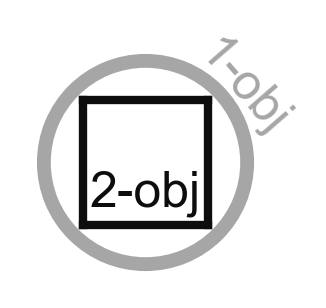

In [8]:
# Self-contained, like the rest of this directory's schematics: the v1 original called
# `ideal_lib.inset_schematic`, whose helpers (`_prep_stim_ax`, `draw_chords`,
# `orientation_grid`) do not exist here — `ideal_lib` was inlined into `ideal_neurons.ipynb`
# and reimplemented in unit-circle coordinates rather than these axes fractions.
import numpy as np
from matplotlib.patches import Annulus


def inset_schematic(sep_deg=90.0, n_orientations=4, radius=0.37, annulus_radius=0.44,
                    annulus_width=0.08, ring_color='0.72', ray_color='0.42', linewidth=2.0,
                    labels=('1-obj', '2-obj'), label_color=None, label_fontsize=None,
                    ring_label_xy=(0.0, 0.56), ring_label_rotation=0.0,
                    ray_label_xy=(0.0, -0.13), ray_label_rotation=0.0, figsize=(1.0, 1.0)):
    """A key for the tuning insets. Returns `(fig, ax)`.

    Geometry is in **axes fractions from the centre** at (0.5, 0.5), so the numbers match the
    v1 original's. `label_color=None` gives each label its own element's grey.

    `label_fontsize=None` takes the style block's `axes.labelsize`, so the key obeys
    `FORMATTING.md`'s 12 pt floor without restating it.
    """
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_aspect('equal'); ax.axis('off')

    ax.add_patch(Annulus((0.5, 0.5), annulus_radius + annulus_width / 2, annulus_width,
                         facecolor=ring_color, edgecolor='none', zorder=2))
    mids = 2 * np.pi * np.arange(n_orientations) / n_orientations
    half = np.radians(sep_deg) / 2
    for m in mids:
        a, b = m - half, m + half
        ax.plot([0.5 + radius * np.cos(a), 0.5 + radius * np.cos(b)],
                [0.5 + radius * np.sin(a), 0.5 + radius * np.sin(b)],
                color=ray_color, lw=linewidth, solid_capstyle='projecting', zorder=3)

    fs = plt.rcParams['axes.labelsize'] if label_fontsize is None else label_fontsize
    for text, xy, rot, colour in ((labels[0], ring_label_xy, ring_label_rotation, ring_color),
                                  (labels[1], ray_label_xy, ray_label_rotation, ray_color)):
        ax.text(0.5 + xy[0], 0.5 + xy[1], text, ha='center', va='center', rotation=rot,
                rotation_mode='anchor', fontsize=fs, color=label_color or colour,
                clip_on=False, zorder=6)
    return fig, ax


fig, _ = inset_schematic(
    sep_deg=KEY_SEP_DEG, n_orientations=KEY_N_ORIENT, figsize=KEY_FIGSIZE,
    radius=KEY_RADIUS, annulus_radius=KEY_ANNULUS_R, annulus_width=KEY_ANNULUS_W,
    linewidth=KEY_LINEWIDTH, ring_color=KEY_RING_COLOR, ray_color=KEY_RAY_COLOR,
    labels=KEY_LABELS,
    ring_label_xy=KEY_RING_LABEL_XY, ring_label_rotation=KEY_RING_LABEL_ROT,
    ray_label_xy=KEY_RAY_LABEL_XY, ray_label_rotation=KEY_RAY_LABEL_ROT)
common.save(fig, OUTPUT_KEY)
plt.show()